In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

In [2]:
df = pd.read_csv("Airlines Dataset.csv")

In [3]:
df.head()

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,01-01-2024,9E,4814,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509,0,0,0,0,0
1,2024,1,1,1,01-01-2024,9E,4815,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622,0,0,0,0,0
2,2024,1,1,1,01-01-2024,9E,4817,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288,0,0,0,0,0
3,2024,1,1,1,01-01-2024,9E,4817,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288,0,0,0,0,0
4,2024,1,1,1,01-01-2024,9E,4818,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237,0,0,0,0,0


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Shape of dataset:", df.shape)

Number of rows: 1048575
Number of columns: 35
Shape of dataset: (1048575, 35)


In [5]:
print(df.columns.tolist())

['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm', 'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off', 'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 35 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   year                 1048575 non-null  int64  
 1   month                1048575 non-null  int64  
 2   day_of_month         1048575 non-null  int64  
 3   day_of_week          1048575 non-null  int64  
 4   fl_date              1048575 non-null  object 
 5   op_unique_carrier    1048575 non-null  object 
 6   op_carrier_fl_num    1048575 non-null  int64  
 7   origin               1048575 non-null  object 
 8   origin_city_name     1048575 non-null  object 
 9   origin_state_nm      1048575 non-null  object 
 10  dest                 1048575 non-null  object 
 11  dest_city_name       1048575 non-null  object 
 12  dest_state_nm        1048575 non-null  object 
 13  crs_dep_time         1048575 non-null  int64  
 14  dep_time             1026022 non-null  float64
 15

In [7]:
df.describe()

,year,month,day_of_month,day_of_week,op_carrier_fl_num,crs_dep_time,dep_time,dep_delay,taxi_out,wheels_off,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,1048575.0,1.048575e+06,1.048575e+06,1.048575e+06,1.048575e+06,1.048575e+06,1.026022e+06,1.025925e+06,1.025450e+06,1.025450e+06,...,1.048575e+06,1.048574e+06,1.022824e+06,1.022824e+06,1.048575e+06,1.048575e+06,1.048575e+06,1.048575e+06,1.048575e+06,1.048575e+06
mean,2024.0,1.478081e+00,1.530512e+01,3.893483e+00,2.354522e+03,1.318681e+03,1.325074e+03,1.167654e+01,1.825012e+01,1.349996e+03,...,2.331736e-03,1.487657e+02,1.425436e+02,1.162270e+02,8.345389e+02,4.705083e+00,1.194321e+00,2.677454e+00,3.474143e-02,5.326660e+00
std,0.0,4.995196e-01,8.585503e+00,2.010038e+00,1.582945e+03,4.845560e+02,4.972990e+02,5.675457e+01,1.044025e+01,4.980426e+02,...,4.823174e-02,7.315623e+01,7.286080e+01,7.091204e+01,5.923104e+02,3.585853e+01,2.005819e+01,1.417420e+01,1.948784e+00,2.975676e+01
min,2024.0,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-9.600000e+01,1.000000e+00,1.000000e+00,...,0.000000e+00,6.000000e+00,1.600000e+01,8.000000e+00,3.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2024.0,1.000000e+00,8.000000e+00,2.000000e+00,1.088000e+03,9.050000e+02,9.110000e+02,-6.000000e+00,1.200000e+01,9.290000e+02,...,0.000000e+00,9.500000e+01,8.900000e+01,6.400000e+01,4.020000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2024.0,1.000000e+00,1.500000e+01,4.000000e+00,2.074000e+03,1.315000e+03,1.323000e+03,-2.000000e+00,1.500000e+01,1.337000e+03,...,0.000000e+00,1.330000e+02,1.270000e+02,1.000000e+02,6.920000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2024.0,2.000000e+00,2.300000e+01,6.000000e+00,3.467000e+03,1.727000e+03,1.736000e+03,8.000000e+00,2.100000e+01,1.750000e+03,...,0.000000e+00,1.800000e+02,1.750000e+02,1.470000e+02,1.069000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2024.0,2.000000e+00,3.100000e+01,7.000000e+00,8.819000e+03,2.359000e+03,2.400000e+03,3.125000e+03,2.130000e+02,2.400000e+03,...,1.000000e+00,8.590000e+02,7.920000e+02,7.230000e+02,5.095000e+03,2.972000e+03,1.804000e+03,1.431000e+03,1.005000e+03,2.100000e+03


In [8]:
df.dtypes

,0
year,int64
month,int64
day_of_month,int64
day_of_week,int64
fl_date,object
op_unique_carrier,object
op_carrier_fl_num,int64
origin,object
origin_city_name,object
origin_state_nm,object


In [9]:
missing = df.isnull().sum().sort_values(ascending=False)

print(missing)

cancellation_code      1025269
actual_elapsed_time      25751
arr_delay                25751
air_time                 25751
wheels_on                23677
taxi_in                  23677
arr_time                 23675
wheels_off               23125
taxi_out                 23125
dep_delay                22650
dep_time                 22553
crs_elapsed_time             1
day_of_month                 0
year                         0
month                        0
dest                         0
day_of_week                  0
op_unique_carrier            0
fl_date                      0
dest_state_nm                0
dest_city_name               0
crs_dep_time                 0
op_carrier_fl_num            0
origin                       0
origin_city_name             0
origin_state_nm              0
crs_arr_time                 0
diverted                     0
cancelled                    0
distance                     0
carrier_delay                0
weather_delay                0
nas_dela

In [10]:
missing_percent = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

print(missing_percent)

cancellation_code      97.777365
actual_elapsed_time     2.455809
arr_delay               2.455809
air_time                2.455809
wheels_on               2.258017
taxi_in                 2.258017
arr_time                2.257826
wheels_off              2.205374
taxi_out                2.205374
dep_delay               2.160074
dep_time                2.150824
crs_elapsed_time        0.000095
day_of_month            0.000000
year                    0.000000
month                   0.000000
dest                    0.000000
day_of_week             0.000000
op_unique_carrier       0.000000
fl_date                 0.000000
dest_state_nm           0.000000
dest_city_name          0.000000
crs_dep_time            0.000000
op_carrier_fl_num       0.000000
origin                  0.000000
origin_city_name        0.000000
origin_state_nm         0.000000
crs_arr_time            0.000000
diverted                0.000000
cancelled               0.000000
distance                0.000000
carrier_de

This calculates the percentage of missing values in each column. Percentage is useful because it shows how large the missing-data problem is compared with the total number of flights.

In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [12]:
print("Unique carriers:", df["op_unique_carrier"].nunique())
print("Unique origins:", df["origin"].nunique())
print("Unique destinations:", df["dest"].nunique())
print("Unique months:", df["month"].nunique())
print("Unique days of week:", df["day_of_week"].nunique())

Unique carriers: 15
Unique origins: 334
Unique destinations: 334
Unique months: 2
Unique days of week: 7


In [13]:
import pandas as pd

# Ensure the dataset is loaded
try:
    _ = df.head()
except NameError:
    df = pd.read_csv("Airlines Dataset.csv")

print("Carriers:")
print(df["op_unique_carrier"].value_counts())

print("\nCancelled flights:")
print(df["cancelled"].value_counts())

print("\nDiverted flights:")
print(df["diverted"].value_counts())

Carriers:
op_unique_carrier
WN    216845
AA    150125
DL    142922
UA    113600
OO    108227
YX     43737
MQ     40121
NK     39603
B6     38096
AS     33997
9E     32628
OH     31623
F9     27975
G4     16646
HA     12430
Name: count, dtype: int64

Cancelled flights:
cancelled
0    1025269
1      23306
Name: count, dtype: int64

Diverted flights:
diverted
0    1046130
1       2445
Name: count, dtype: int64


This step looks at the distribution of airlines and the number of cancelled and diverted flights. Cancelled and diverted flights need special attention because they may not have a normal arrival delay.

In [14]:
df["fl_date"] = pd.to_datetime(df["fl_date"], dayfirst=True, errors="coerce")

print(df["fl_date"].head())
print(df["fl_date"].dtype)

0   2024-01-01
1   2024-01-01
2   2024-01-01
3   2024-01-01
4   2024-01-01
Name: fl_date, dtype: datetime64[ns]
datetime64[ns]


This converts the flight date column into a proper datetime format. This makes it easier to extract useful information from the date and perform time-based analysis.

In [15]:
df["dep_hour"] = df["crs_dep_time"] // 100

df["is_weekend"] = df["day_of_week"].isin([6, 7]).astype(int)

print(df[["crs_dep_time", "dep_hour", "day_of_week", "is_weekend"]].head())

   crs_dep_time  dep_hour  day_of_week  is_weekend
0          1252        12            1           0
1          1015        10            1           0
2          1415        14            1           0
3          1650        16            1           0
4          1015        10            1           0


This creates two simple features for analysis. dep_hour represents the scheduled departure hour, while is_weekend identifies Saturday and Sunday flights. These features can help study whether departure time or weekends are related to delays.

In [16]:
print("Cancelled flights:", df["cancelled"].sum())
print("Diverted flights:", df["diverted"].sum())

Cancelled flights: 23306
Diverted flights: 2445


In [17]:
data = df[(df["cancelled"] == 0) & (df["diverted"] == 0)].copy()

data = data.dropna(subset=["arr_delay"])

print("Rows available for delay analysis:", len(data))

Rows available for delay analysis: 1022824


In [18]:
data["delay_status"] = (data["arr_delay"] > 15).astype(int)

print(data["delay_status"].value_counts())

delay_status
0    824148
1    198676
Name: count, dtype: int64


The target variable delay_status represents whether a flight arrived more than 15 minutes late. A value of 1 means delayed by more than 15 minutes, while 0 means it was not delayed beyond this threshold.

In [19]:
target_count = data["delay_status"].value_counts()

print(target_count)

print("\nTarget percentage:")
print(data["delay_status"].value_counts(normalize=True) * 100)

delay_status
0    824148
1    198676
Name: count, dtype: int64

Target percentage:
delay_status
0    80.575739
1    19.424261
Name: proportion, dtype: float64


This checks how many flights belong to each target class and calculates their percentages. This is important because a large difference between the two classes can affect model performance and interpretation.

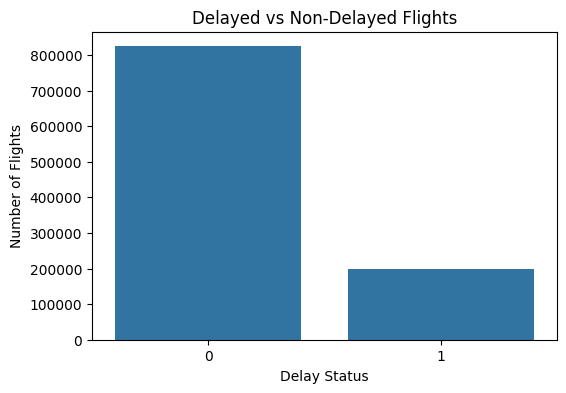

In [20]:
plt.figure(figsize=(6, 4))

sns.countplot(x="delay_status", data=data)

plt.title("Delayed vs Non-Delayed Flights")
plt.xlabel("Delay Status")
plt.ylabel("Number of Flights")

plt.show()

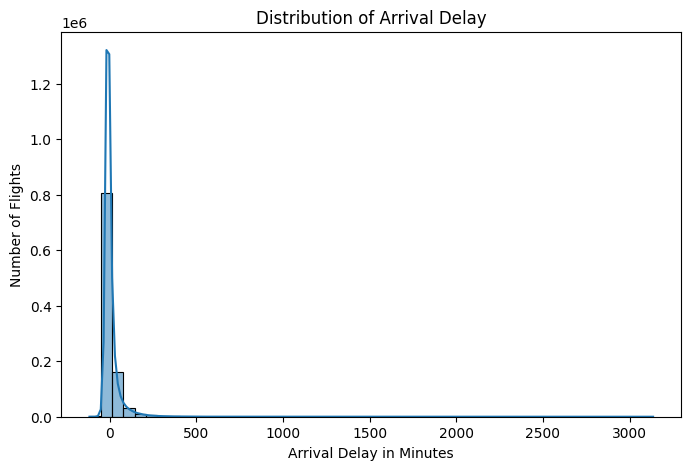

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(data["arr_delay"], bins=50, kde=True)

plt.title("Distribution of Arrival Delay")
plt.xlabel("Arrival Delay in Minutes")
plt.ylabel("Number of Flights")

plt.show()

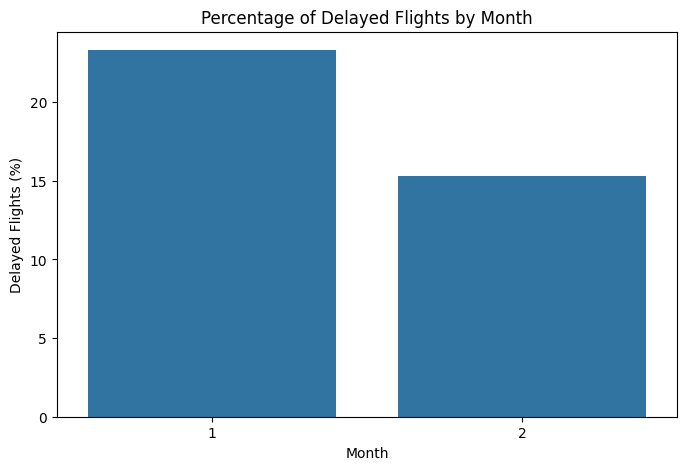

In [22]:
monthly_delay = data.groupby("month")["delay_status"].mean() * 100

plt.figure(figsize=(8, 5))

sns.barplot(x=monthly_delay.index, y=monthly_delay.values)

plt.title("Percentage of Delayed Flights by Month")
plt.xlabel("Month")
plt.ylabel("Delayed Flights (%)")

plt.show()

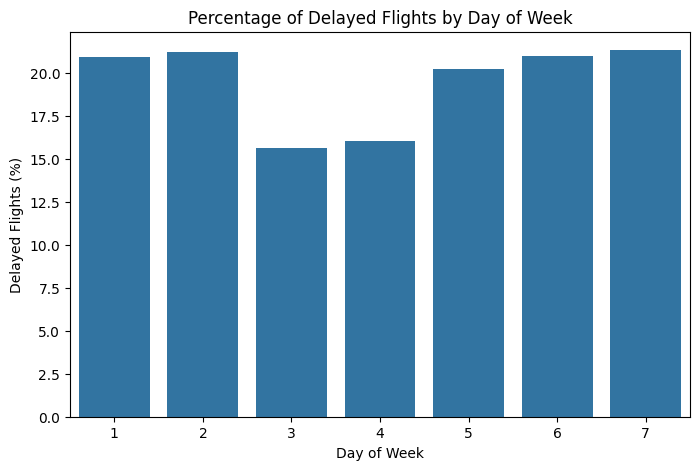

In [23]:
weekly_delay = data.groupby("day_of_week")["delay_status"].mean() * 100

plt.figure(figsize=(8, 5))

sns.barplot(x=weekly_delay.index, y=weekly_delay.values)

plt.title("Percentage of Delayed Flights by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Delayed Flights (%)")

plt.show()

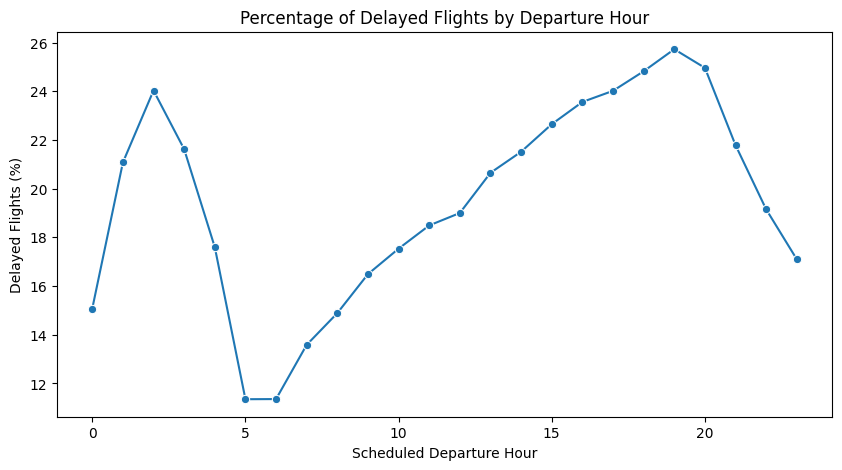

In [24]:
hourly_delay = data.groupby("dep_hour")["delay_status"].mean() * 100

plt.figure(figsize=(10, 5))

sns.lineplot(x=hourly_delay.index, y=hourly_delay.values, marker="o")

plt.title("Percentage of Delayed Flights by Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Delayed Flights (%)")

plt.show()

This shows how the percentage of delayed flights changes throughout the day. Departure time can be useful because delays may increase during certain periods of the day.

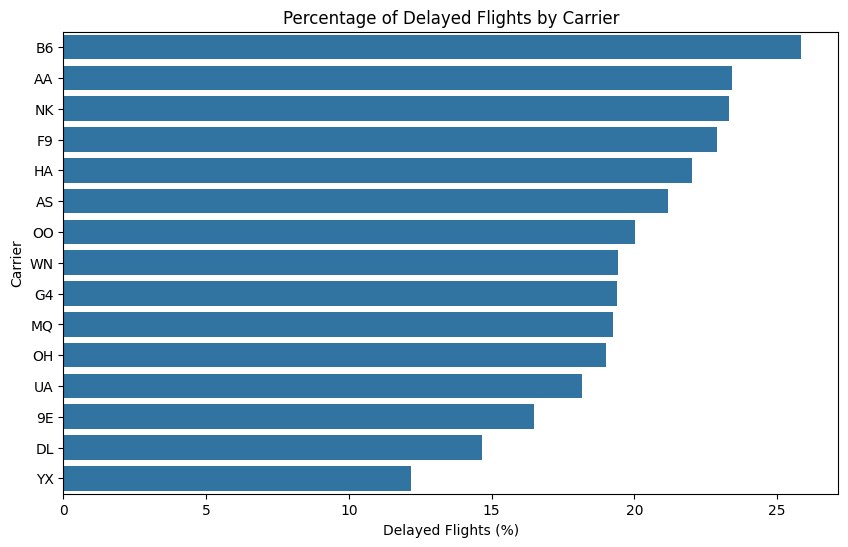

In [25]:
carrier_delay = data.groupby("op_unique_carrier")["delay_status"].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 6))

sns.barplot(x=carrier_delay.values, y=carrier_delay.index)

plt.title("Percentage of Delayed Flights by Carrier")
plt.xlabel("Delayed Flights (%)")
plt.ylabel("Carrier")

plt.show()

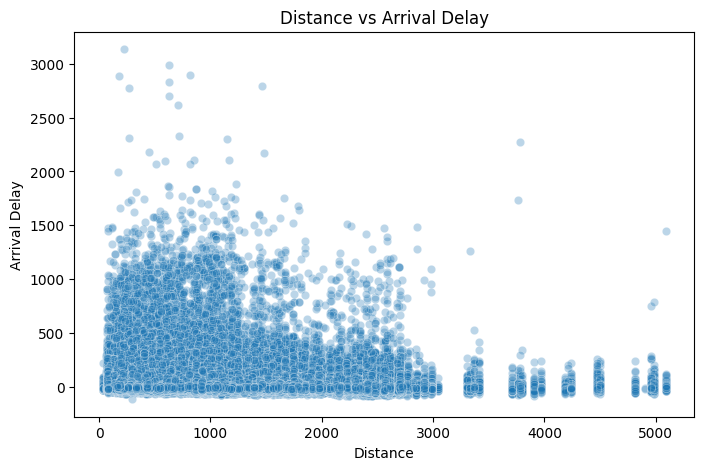

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=data["distance"],
    y=data["arr_delay"],
    alpha=0.3
)

plt.title("Distance vs Arrival Delay")
plt.xlabel("Distance")
plt.ylabel("Arrival Delay")

plt.show()

This graph checks the relationship between flight distance and arrival delay. The points show whether longer or shorter flights appear to have any clear relationship with delay.

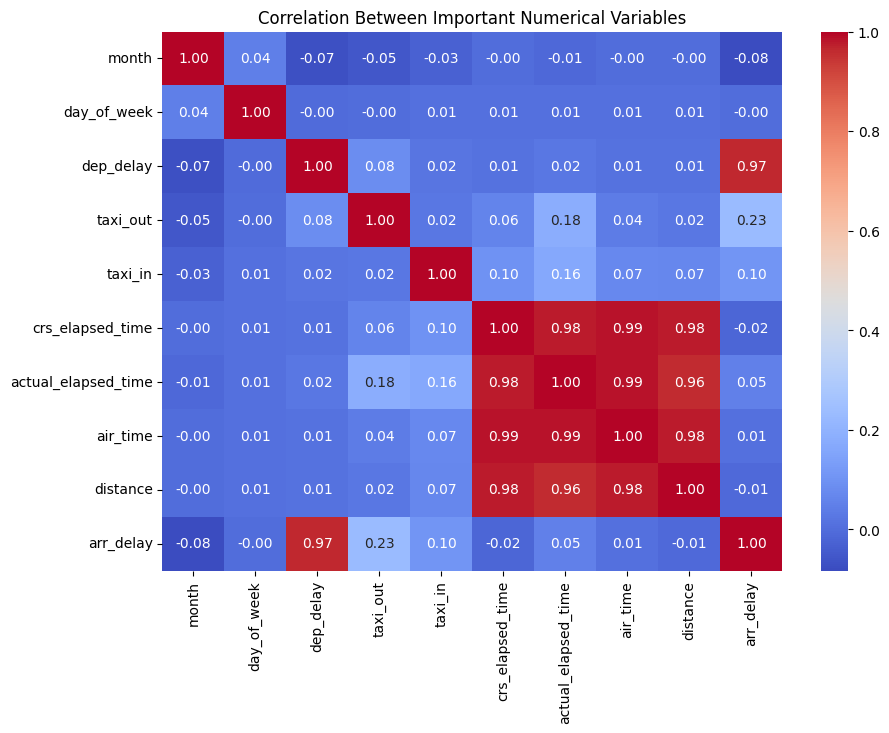

In [27]:
numeric_cols = [
    "month",
    "day_of_week",
    "dep_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance",
    "arr_delay"
]

corr = data[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Important Numerical Variables")

plt.show()

In [28]:
print(
    corr["arr_delay"]
    .sort_values(ascending=False)
)

arr_delay              1.000000
dep_delay              0.966141
taxi_out               0.229520
taxi_in                0.104059
actual_elapsed_time    0.049683
air_time               0.007781
day_of_week           -0.001329
distance              -0.009882
crs_elapsed_time      -0.015450
month                 -0.082789
Name: arr_delay, dtype: float64


Prepare Baseline Features

In [29]:
features = [
    "month",
    "day_of_week",
    "dep_hour",
    "crs_elapsed_time",
    "distance",
    "op_unique_carrier",
    "origin",
    "dest"
]

model_data = data[features + ["delay_status"]].copy()

model_data.head()

,month,day_of_week,dep_hour,crs_elapsed_time,distance,op_unique_carrier,origin,dest,delay_status
0,1,1,12,136.0,509,9E,JFK,DTW,0
1,1,1,10,130.0,622,9E,MSP,CLE,0
2,1,1,14,106.0,288,9E,JFK,RIC,0
3,1,1,16,111.0,288,9E,RIC,JFK,0
4,1,1,10,79.0,237,9E,DTW,MKE,0


This selects a small set of features for the first baseline model. The features include scheduled flight information, airline, origin, destination, distance and scheduled departure time. Variables containing the actual arrival outcome are not included.

In [30]:
print(model_data.isnull().sum())

month                0
day_of_week          0
dep_hour             0
crs_elapsed_time     0
distance             0
op_unique_carrier    0
origin               0
dest                 0
delay_status         0
dtype: int64


In [31]:
numeric_cols = [
    "month",
    "day_of_week",
    "dep_hour",
    "crs_elapsed_time",
    "distance"
]

for col in numeric_cols:
    model_data[col] = model_data[col].fillna(model_data[col].median())

categorical_cols = [
    "op_unique_carrier",
    "origin",
    "dest"
]

for col in categorical_cols:
    model_data[col] = model_data[col].fillna(model_data[col].mode()[0])

print(model_data.isnull().sum())

month                0
day_of_week          0
dep_hour             0
crs_elapsed_time     0
distance             0
op_unique_carrier    0
origin               0
dest                 0
delay_status         0
dtype: int64


In [32]:
model_data = pd.get_dummies(
    model_data,
    columns=["op_unique_carrier", "origin", "dest"],
    drop_first=True
)

print("Shape after encoding:", model_data.shape)

Shape after encoding: (1022824, 686)


In [33]:
X = model_data.drop("delay_status", axis=1)
y = model_data["delay_status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1022824, 685)
y shape: (1022824,)


X contains the input features and y contains the target variable. The model will use the information in X to predict whether the flight belongs to the delayed or non-delayed class.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 818259
Testing rows: 204565


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

print("1. Loading dataset...")
df = pd.read_csv("Airlines Dataset.csv")

print("2. Filtering and downsampling (10% sample for fast training)...")
data = df[(df["cancelled"] == 0) & (df["diverted"] == 0)].copy()
data = data.dropna(subset=["arr_delay"])

# Sample 10% of the data to speed up CPU training significantly
data_sample = data.sample(frac=0.10, random_state=42)
data_sample["delay_status"] = (data_sample["arr_delay"] > 15).astype(int)
data_sample["dep_hour"] = data_sample["crs_dep_time"] // 100

# 3. Handle features and missing values
features = ["month", "day_of_week", "dep_hour", "crs_elapsed_time", "distance", "op_unique_carrier", "origin", "dest"]
model_data = data_sample[features + ["delay_status"]].copy()

numeric_cols = ["month", "day_of_week", "dep_hour", "crs_elapsed_time", "distance"]
for col in numeric_cols:
    model_data[col] = model_data[col].fillna(model_data[col].median())

categorical_cols = ["op_unique_carrier", "origin", "dest"]
for col in categorical_cols:
    model_data[col] = model_data[col].fillna(model_data[col].mode()[0])

print("4. Encoding categorical variables (One-Hot)...")
model_data = pd.get_dummies(model_data, columns=categorical_cols, drop_first=True)

X = model_data.drop("delay_status", axis=1)
y = model_data["delay_status"]

# 5. Split train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("6. Scaling numerical features...")
scaler = StandardScaler()
# Match columns actually present in X_train
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("7. Training Logistic Regression baseline model with saga solver...")
# Use 'saga' solver with a smaller tolerance for extremely fast convergence on sample data
model = LogisticRegression(max_iter=250, solver="saga", tol=1e-3, n_jobs=-1)
model.fit(X_train, y_train)

print("\nModel training complete!")
print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

1. Loading dataset...
2. Filtering and downsampling (10% sample for fast training)...
4. Encoding categorical variables (One-Hot)...
6. Scaling numerical features...
7. Training Logistic Regression baseline model with saga solver...

Model training complete!
Train set shape: (81825, 681)
Test set shape: (20457, 681)


In [2]:
print("8. Making predictions...")

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print("Predictions completed.")

8. Making predictions...
Predictions completed.


In [3]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, pred)

print("Baseline Accuracy:", accuracy)

Baseline Accuracy: 0.8059832820061592


In [4]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, prob)

print("Baseline ROC-AUC:", auc)

Baseline ROC-AUC: 0.6332114165447105


In [5]:
print("Flight Delay Prediction - Baseline Results")
print("--------------------------------------------")
print("Accuracy :", accuracy)
print("ROC-AUC  :", auc)

Flight Delay Prediction - Baseline Results
--------------------------------------------
Accuracy : 0.8059832820061592
ROC-AUC  : 0.6332114165447105
